In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

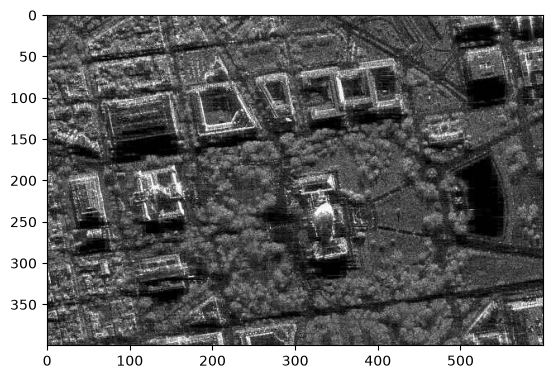

In [9]:

#img - вывелся img

image = cv2.imread('sar_1_gray.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap="gray")

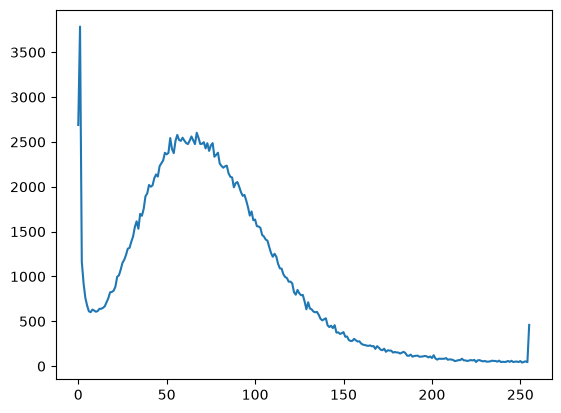

In [ ]:
#гистограмма - вывелась гистограмма
histSize = 256
histRange = (0, 256)
accumulate = False
b_hist = cv2.calcHist([image], [0], None, [histSize], histRange, accumulate=accumulate)

plt.plot(b_hist)

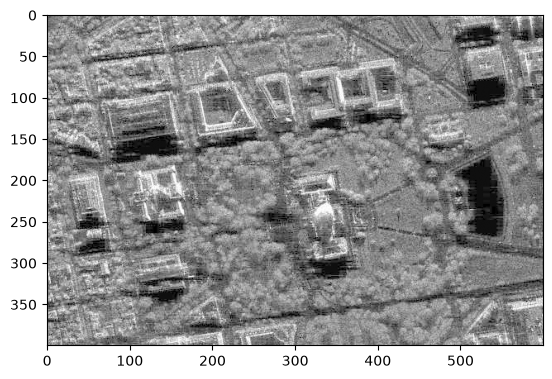

In [ ]:
#гамма коррекция

# гамма < 1 (светлее)
gamma1 = 0.5
image_gamma1 = 255 * (image / 255) ** gamma1
image_gamma1 = image_gamma1.astype(np.uint8)

plt.imshow(image_gamma1, cmap="gray")

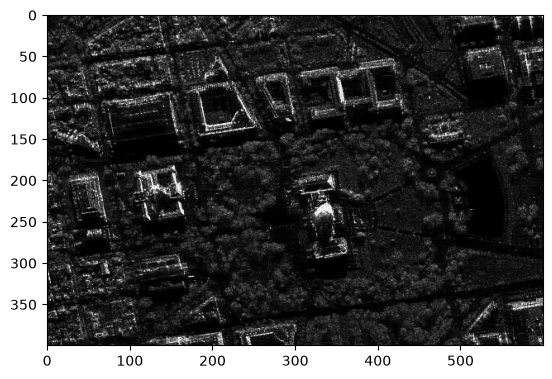

In [13]:
# гамма > 1 (темнее)
gamma2 = 2.0
image_gamma2 = 255 * (image / 255) ** gamma2
image_gamma2 = image_gamma2.astype(np.uint8)

plt.imshow(image_gamma2, cmap="gray")

MSE: 3250.429145833333
SSIM: 0.7875008686792752


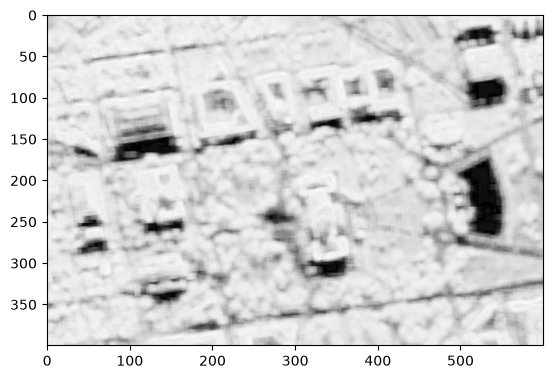

In [16]:
# сравнение изображений скорректированное при помощи гамма-фильтра. MSE, SSIM

mse = mean_squared_error(image, image_gamma1)

(ssim, diff) = structural_similarity(image, image_gamma1, full=True)

diff = (diff * 255).astype("uint8")

print("MSE:", mse)
print("SSIM:", ssim)

plt.imshow(diff, cmap="gray")

74.94157083333333 43.658465466227916
127.02563333333333 74.26964841889017
123.1181375 65.3025763098039


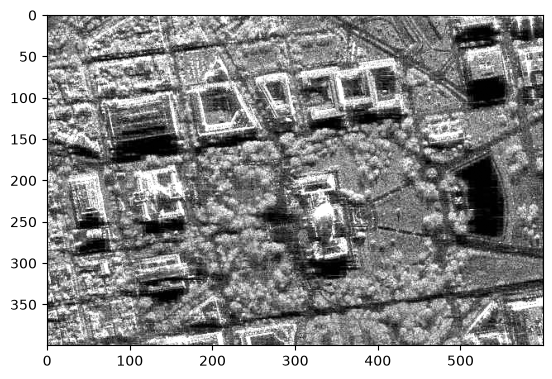

In [ ]:
# алгоритм статистической цветокоррекции

mean = image.mean() #средняя яркость
std = image.std() #среднее отклонение яркости

print(mean, std) #исходник

eq_gray = cv2.equalizeHist(image)

eq_mean = eq_gray.mean()
eq_std = eq_gray.std()
print(eq_mean, eq_std)  #выровненный

result = image.astype(np.float32)

result = (result - mean) / std * eq_std + eq_mean 
result = np.clip(result, 0, 255).astype(np.uint8)

print(result.mean() , result.std())

plt.imshow(result, cmap="gray")

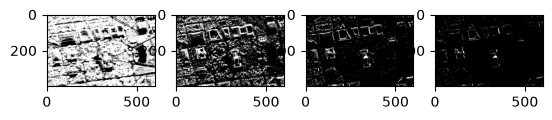

In [21]:
# пороговая фильтрация

_, threshold1 = cv2.threshold(image, 50, 255, cv2.THRESH_BINARY)
_, threshold2 = cv2.threshold(image, 100, 255, cv2.THRESH_BINARY)
_, threshold3 = cv2.threshold(image, 150, 255, cv2.THRESH_BINARY)
_, threshold4 = cv2.threshold(image, 200, 255, cv2.THRESH_BINARY)

plt.subplot(1, 4, 1)
plt.imshow(threshold1, cmap="gray")
plt.subplot(1, 4, 2)
plt.imshow(threshold2, cmap="gray")
plt.subplot(1, 4, 3)
plt.imshow(threshold3, cmap="gray")
plt.subplot(1, 4, 4)
plt.imshow(threshold4, cmap="gray")

# 1. Загрузите изображение в оттенках серого sar_1_gray.jpg. 
# 2. постройте гистограмму
# 3. реализуйте алгоритм гамма коррекции с параметром гамма <1, >1.
# 4. Сравните исходное изображение, скорректированное при помощи гамма-фильтра. MSE, SSIM.
# 5. реализуйте алгоритм статистической цветокоррекции на основе статистики eq_gray.
# 6. Протестируйте работу алгоритмов пороговой фильтрации с различными параметрами.
# Для каждого решения - напечатайте результат